# Chapitre 5 - Cours 5 : détecter les écritures concurrentes

Multi-leader ou sans leader, plusieurs clients peuvent écrire la même clé en même temps,
et les écritures arrivent dans des ordres différents selon les répliques. Pour converger
sans perdre de données, il faut savoir distinguer une écriture qui **remplace** une autre
(elle l'a vue) d'une écriture **concurrente** (elle l'ignorait). Ce cours couvre la
section *Detecting Concurrent Writes* : *Last write wins*, *The "happens-before" relationship and concurrency*, *Capturing the happens-before relationship*, *Merging concurrently written values* et *Version vectors*.

**Plan.**

1. Pas d'ordre bien défini.
2. La relation « arrivé avant ».
3. Capturer la relation sur une réplique : le panier d'achat.
4. Fusionner les frères.
5. Vecteurs de versions, sur plusieurs répliques.

In [1]:
import itertools
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Pas d'ordre bien défini (section *Detecting Concurrent Writes*)

Deux clients, A et B, écrivent la clé X en même temps dans une base sans leader à trois
nœuds. Le nœud 1 reçoit l'écriture de A mais jamais celle de B (coupure passagère) ; le
nœud 2 reçoit A puis B ; le nœud 3 reçoit B puis A. Si chaque nœud **écrase** simplement la
valeur à chaque écriture reçue, les répliques divergent pour toujours.

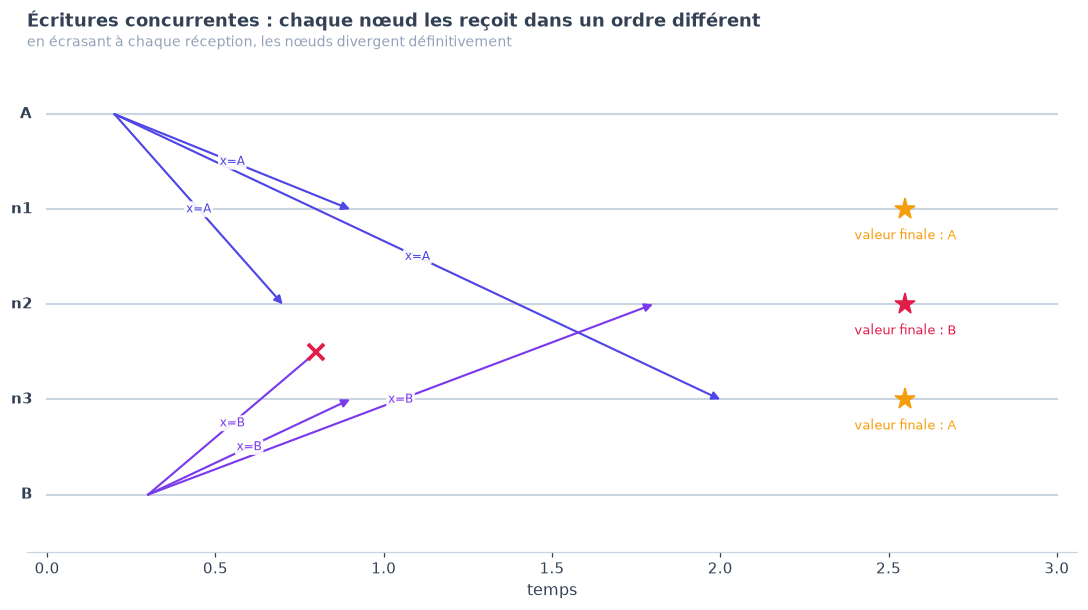

In [2]:
class Ecrase(Node):
    def __init__(self, name):
        super().__init__(name)
        self.x = None
    def on_message(self, src, msg):
        if msg[0] == "set":
            self.x = msg[1]
            self.record(f"x={msg[1]}")

def latence(rng, src, dst):
    table = {("A", "n2"): 0.5, ("B", "n2"): 1.5, ("A", "n3"): 1.8, ("B", "n3"): 0.6, ("A", "n1"): 0.7}
    return table.get((src, dst), 1.0)

net = Network(seed=0, latency=latence)
noeuds = {n: net.add(Ecrase(n)) for n in ("n1", "n2", "n3")}
A, B = net.add(Node("A")), net.add(Node("B"))
net.block("B", "n1")
for n in noeuds:
    net.at(0.2, A.send, n, ("set", "A"))
    net.at(0.3, B.send, n, ("set", "B"))
net.run()
st = SpaceTime(["A", "n1", "n2", "n3", "B"], t_max=3, width=10,
               title="Écritures concurrentes : chaque nœud les reçoit dans un ordre différent",
               subtitle="en écrasant à chaque réception, les nœuds divergent définitivement")
st.from_trace(net.trace, color_of=lambda d: INDIGO if d.src == "A" else VIOLET, label_of=lambda d: f"x={d.msg[1]}")
for n, node in noeuds.items():
    st.event(n, 2.55, f"valeur finale : {node.x}", kind="star", color=ROSE if node.x != "A" else AMBER)
st.show()

`n2` termine avec B, `n1` et `n3` avec A : la base n'est pas cohérente, même « à terme ».
Pour converger, il faut une règle de résolution (cours 3) : LWW (Cassandra), résolution
manuelle avec frères (Riak).

**LWW** (dernier écrivain gagnant) est le plus simple : chaque écriture porte un
horodatage, la plus grande gagne partout. Mais un horodatage ne dit pas si deux valeurs
sont **réellement concurrentes** ou **successives** : LWW écrase de la même façon une
valeur que l'écrivain avait vue (légitime) et une valeur qu'il ignorait (perte de
données). Pour résoudre les conflits proprement, il faut **détecter** la concurrence.

> **À retenir.** Faute d'ordre global, des répliques qui écrasent à chaque réception
> divergent. Converger exige une règle commune ; ne rien perdre exige de savoir quelles
> écritures sont concurrentes.